<a href="https://colab.research.google.com/github/boukadil/Python-pour-la-physique/blob/main/07_pandas_Adil_BOUKALI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

07_pandas

In [1]:
# Cellule de préparation (facultative) : exécutez-la une fois au début.
# Sur Google Colab, NumPy, SciPy, Matplotlib et SymPy sont déjà installés.
import sys
EN_COLAB = 'google.colab' in sys.modules
print('Exécution dans Google Colab' if EN_COLAB else 'Exécution en local')

Exécution dans Google Colab


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
mesures = pd.DataFrame({
    'longueur_m': [0.20, 0.40, 0.60, 0.80, 1.00, 1.20],
    'periode_s':  [0.90, 1.27, 1.55, 1.79, 2.01, 2.20],
})
mesures

,longueur_m,periode_s
0,0.2,0.90
1,0.4,1.27
2,0.6,1.55
3,0.8,1.79
4,1.0,2.01
5,1.2,2.20


On peut aussi partir de tableaux NumPy :

In [4]:
t = np.linspace(-6, 6, 20)
pd.DataFrame({'t': t, 'sin': np.sin(t), 'cos': np.cos(t)}).head()

,t,sin,cos
0,-6.000000,0.279415,0.960170
1,-5.368421,0.792419,0.609977
2,-4.736842,0.999701,0.024451
3,-4.105263,0.821291,-0.570509
4,-3.473684,0.326021,-0.945363


In [5]:
rng = np.random.default_rng(12)
noms = ['Alice', 'Bruno', 'Chloé', 'David']
lignes = []
for operateur in noms:
    for L in [0.25, 0.50, 0.75, 1.00]:
        T = 2 * np.pi * np.sqrt(L / 9.81) * (1 + rng.normal(0, 0.02))
        lignes.append((operateur, L, round(T, 3), 0.1 if L < 0.7 else 0.2))
df_brut = pd.DataFrame(lignes, columns=['operateur', 'longueur_m', 'periode_s', 'masse_kg'])
df_brut.loc[5, 'periode_s'] = np.nan          # une mesure oubliée
df_brut.to_csv('pendule.csv', sep=';', index=False, decimal=',')
print(open('pendule.csv').read()[:300])

operateur;longueur_m;periode_s;masse_kg
Alice;0,25;1,003;0,1
Alice;0,5;1,448;0,1
Alice;0,75;1,763;0,2
Alice;1,0;2,035;0,2
Bruno;0,25;1,036;0,1
Bruno;0,5;;0,1
Bruno;0,75;1,716;0,2
Bruno;1,0;1,953;0,2
Chloé;0,25;1,001;0,1
Chloé;0,5;1,447;0,1
Chloé;0,75;1,737;0,2
Chloé;1,0;2,026;0,2
David;0,25;0,965;0,


In [6]:
df = pd.read_csv('pendule.csv', sep=';', decimal=',')
df

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2
4,Bruno,0.25,1.036,0.1
5,Bruno,0.50,NaN,0.1
6,Bruno,0.75,1.716,0.2
7,Bruno,1.00,1.953,0.2
8,Chloé,0.25,1.001,0.1
9,Chloé,0.50,1.447,0.1


# Explorer les données

In [7]:
df.shape          # (lignes, colonnes)

(16, 4)

In [8]:
df.columns        # noms des colonnes

Index(['operateur', 'longueur_m', 'periode_s', 'masse_kg'], dtype='object')

In [9]:
df.head()         # les premières lignes (df.tail() pour les dernières)

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2
4,Bruno,0.25,1.036,0.1


In [10]:
df.info()         # types des colonnes et nombre de valeurs non manquantes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   operateur   16 non-null     object 
 1   longueur_m  16 non-null     float64
 2   periode_s   15 non-null     float64
 3   masse_kg    16 non-null     float64
dtypes: float64(3), object(1)
memory usage: 644.0+ bytes


In [11]:
df.describe()

,longueur_m,periode_s,masse_kg
count,16.000000,15.000000,16.00000
mean,0.625000,1.555733,0.15000
std,0.288675,0.403365,0.05164
min,0.250000,0.965000,0.10000
25%,0.437500,1.229500,0.10000
50%,0.625000,1.706000,0.15000
75%,0.812500,1.858000,0.20000
max,1.000000,2.077000,0.20000


In [12]:
df['periode_s']

,periode_s
0,1.003
1,1.448
2,1.763
3,2.035
4,1.036
5,NaN
6,1.716
7,1.953
8,1.001
9,1.447


**Plusieurs colonnes** (le résultat est un `DataFrame`) :

In [13]:
df[['operateur', 'periode_s']]

,operateur,periode_s
0,Alice,1.003
1,Alice,1.448
2,Alice,1.763
3,Alice,2.035
4,Bruno,1.036
5,Bruno,NaN
6,Bruno,1.716
7,Bruno,1.953
8,Chloé,1.001
9,Chloé,1.447


**Des lignes**, par position avec `iloc`, ou par étiquette avec `loc` :

In [14]:
df.iloc[0:3]                   # trois premières lignes

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2


In [15]:
df.loc[0:3, ['longueur_m', 'periode_s']]   # attention : avec loc, la borne 3 est incluse

,longueur_m,periode_s
0,0.25,1.003
1,0.50,1.448
2,0.75,1.763
3,1.00,2.035


**Des lignes qui vérifient une condition** (filtre booléen, comme les masques NumPy) :

In [16]:
df[df['operateur'] == 'Alice']

,operateur,longueur_m,periode_s,masse_kg
0,Alice,0.25,1.003,0.1
1,Alice,0.50,1.448,0.1
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2


In [17]:
df[(df['longueur_m'] >= 0.5) & (df['masse_kg'] == 0.2)]    # & = ET, | = OU, ~ = NON

,operateur,longueur_m,periode_s,masse_kg
2,Alice,0.75,1.763,0.2
3,Alice,1.00,2.035,0.2
6,Bruno,0.75,1.716,0.2
7,Bruno,1.00,1.953,0.2
10,Chloé,0.75,1.737,0.2
11,Chloé,1.00,2.026,0.2
14,David,0.75,1.706,0.2
15,David,1.00,2.077,0.2


Moyenne d'une sélection :

In [18]:
df[df['operateur'] == 'Alice']['periode_s'].mean()

np.float64(1.56225)

# Créer de nouvelles colonnes

Les opérations se font colonne par colonne, comme avec NumPy. Calculons la valeur de $g$ déduite de chaque mesure, avec $g = 4\pi^2 L / T^2$ :

In [19]:
df['g'] = 4 * np.pi**2 * df['longueur_m'] / df['periode_s']**2
df.head()

,operateur,longueur_m,periode_s,masse_kg,g
0,Alice,0.25,1.003,0.1,9.810652
1,Alice,0.50,1.448,0.1,9.414399
2,Alice,0.75,1.763,0.2,9.526127
3,Alice,1.00,2.035,0.2,9.533029
4,Bruno,0.25,1.036,0.1,9.195603


Les fonctions NumPy s'appliquent directement aux colonnes :

In [20]:
df['log_T'] = np.log10(df['periode_s'])
df[['periode_s', 'log_T']].head(3)

,periode_s,log_T
0,1.003,0.001301
1,1.448,0.160769
2,1.763,0.246252


# Valeurs manquantes

In [21]:
df.isna().sum()          # nombre de valeurs manquantes par colonne

,0
operateur,0
longueur_m,0
periode_s,1
masse_kg,0
g,1
log_T,1


In [22]:
df[df['periode_s'].isna()]     # la ligne concernée

,operateur,longueur_m,periode_s,masse_kg,g,log_T
5,Bruno,0.5,NaN,0.1,NaN,NaN


In [23]:
df_propre = df.dropna()                  # supprime les lignes contenant un NaN
print(len(df), "->", len(df_propre))

16 -> 15


In [24]:
df['periode_s'].fillna(df['periode_s'].mean()).head(8)   # remplace par la moyenne (à utiliser avec prudence !)

,periode_s
0,1.003000
1,1.448000
2,1.763000
3,2.035000
4,1.036000
5,1.555733
6,1.716000
7,1.953000


# Regrouper et agréger : `groupby`

`groupby` découpe un tableau selon les valeurs d'une variable catégorielle (ici l'opérateur), puis calcule une statistique pour chaque groupe :

In [25]:
df_propre = df.dropna()
df_propre.groupby('operateur')['g'].mean()

,g
operateur,
Alice,9.571052
Bruno,9.867020
Chloé,9.677167
David,9.917831


Plusieurs statistiques à la fois avec `agg` :

In [26]:
df_propre.groupby('operateur')['g'].agg(['count', 'mean', 'std'])

,count,mean,std
operateur,,,
Alice,4,9.571052,0.168733
Bruno,3,9.867020,0.599911
Chloé,4,9.677167,0.195186
David,4,9.917831,0.617755


On peut regrouper selon plusieurs colonnes :

In [27]:
df_propre.groupby(['masse_kg', 'longueur_m'])['periode_s'].mean()

masse_kg  longueur_m
0.1       0.25          1.001250
          0.50          1.439333
0.2       0.75          1.730500
          1.00          2.022750
Name: periode_s, dtype: float64

Et obtenir directement toutes les moyennes d'un tableau groupé :

In [28]:
df_propre.groupby('operateur')[['periode_s', 'g']].mean()

,periode_s,g
operateur,,
Alice,1.562250,9.571052
Bruno,1.568333,9.867020
Chloé,1.552750,9.677167
David,1.542750,9.917831


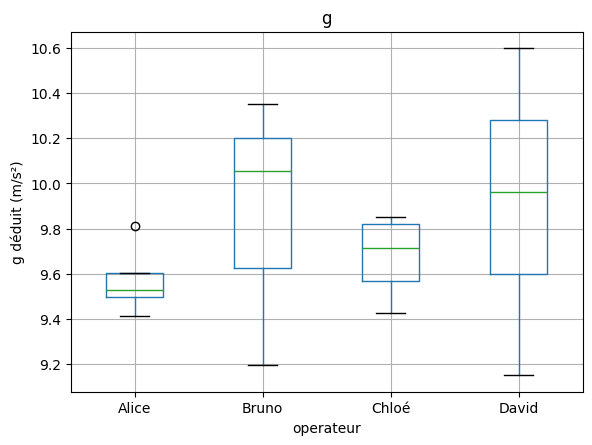

In [29]:
df_propre.boxplot(column='g', by='operateur')
plt.suptitle("")
plt.ylabel("g déduit (m/s²)")
plt.show()

In [30]:
# Votre code ici

In [31]:
#@title Solution { display-mode: "form" }
print("g moyen :", df_propre['g'].mean())
print(df_propre.groupby('operateur')['g'].count())
print(df_propre.groupby('longueur_m')['periode_s'].mean())

g moyen : 9.751017258593095
operateur
Alice    4
Bruno    3
Chloé    4
David    4
Name: g, dtype: int64
longueur_m
0.25    1.001250
0.50    1.439333
0.75    1.730500
1.00    2.022750
Name: periode_s, dtype: float64


# Trier, renommer, supprimer

In [32]:
df_propre.sort_values('g', ascending=False).head(3)       # les 3 plus grandes valeurs de g

,operateur,longueur_m,periode_s,masse_kg,g,log_T
12,David,0.25,0.965,0.1,10.598517,-0.015473
7,Bruno,1.00,1.953,0.2,10.350355,0.290702
14,David,0.75,1.706,0.2,10.173326,0.231979


In [33]:
df_propre.rename(columns={'periode_s': 'T (s)', 'longueur_m': 'L (m)'}).head(3)

,operateur,L (m),T (s),masse_kg,g,log_T
0,Alice,0.25,1.003,0.1,9.810652,0.001301
1,Alice,0.50,1.448,0.1,9.414399,0.160769
2,Alice,0.75,1.763,0.2,9.526127,0.246252


In [34]:
df_propre.drop(columns=['log_T']).head(3)

,operateur,longueur_m,periode_s,masse_kg,g
0,Alice,0.25,1.003,0.1,9.810652
1,Alice,0.50,1.448,0.1,9.414399
2,Alice,0.75,1.763,0.2,9.526127


In [35]:
incertitudes = pd.DataFrame({'longueur_m': [0.25, 0.50, 0.75, 1.00],
                             'u_L_mm': [1, 1, 2, 2]})
fusion = df_propre.merge(incertitudes, on='longueur_m')
fusion[['operateur', 'longueur_m', 'u_L_mm']].head()

,operateur,longueur_m,u_L_mm
0,Alice,0.25,1
1,Alice,0.50,1
2,Alice,0.75,2
3,Alice,1.00,2
4,Bruno,0.25,1


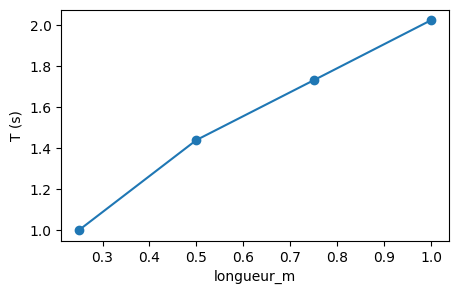

In [36]:
moyennes = df_propre.groupby('longueur_m')['periode_s'].mean()
moyennes.plot(marker='o', figsize=(5, 3))
plt.ylabel("T (s)")
plt.show()

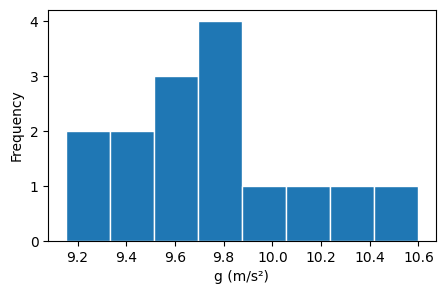

In [37]:
df_propre['g'].plot(kind='hist', bins=8, edgecolor='white', figsize=(5, 3))
plt.xlabel("g (m/s²)")
plt.show()

Pour des figures plus abouties, on extrait les colonnes et on utilise Matplotlib directement :

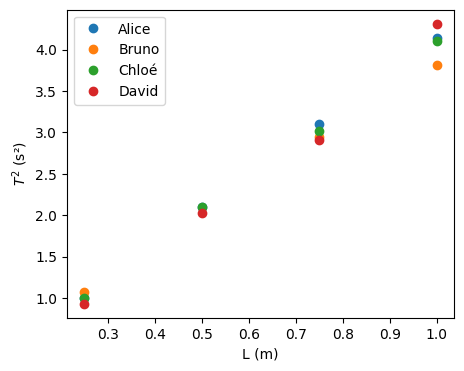

In [38]:
fig, ax = plt.subplots(figsize=(5, 4))
for operateur, groupe in df_propre.groupby('operateur'):
    ax.plot(groupe['longueur_m'], groupe['periode_s']**2, 'o', label=operateur)
ax.set_xlabel("L (m)")
ax.set_ylabel(r"$T^2$ (s²)")
ax.legend()
plt.show()

In [39]:
rng = np.random.default_rng(5)
temps = np.arange(0, 1800, 30)
T_amb, T0, tau = 21.0, 85.0, 600.0
T_mes = T_amb + (T0 - T_amb) * np.exp(-temps / tau) + rng.normal(0, 0.3, temps.size)

refroid = pd.DataFrame({'t_s': temps, 'T_C': T_mes.round(2)})
refroid.to_csv('refroidissement.csv', index=False)
refroid = pd.read_csv('refroidissement.csv')
refroid.head()

,t_s,T_C
0,0,84.76
1,30,81.48
2,60,78.84
3,90,76.21
4,120,73.74


Ajoutons une colonne en minutes et calculons une moyenne glissante pour lisser le bruit :

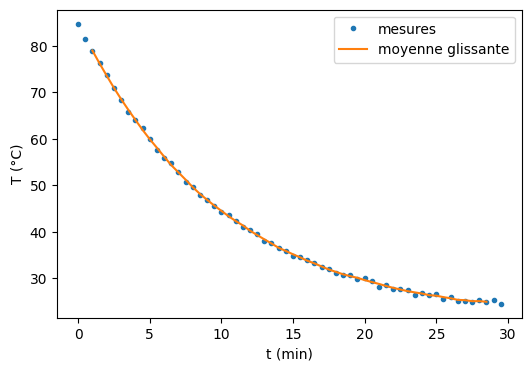

In [40]:
refroid['t_min'] = refroid['t_s'] / 60
refroid['T_lisse'] = refroid['T_C'].rolling(window=5, center=True).mean()

plt.figure(figsize=(6, 4))
plt.plot(refroid['t_min'], refroid['T_C'], '.', label="mesures")
plt.plot(refroid['t_min'], refroid['T_lisse'], '-', label="moyenne glissante")
plt.xlabel("t (min)"); plt.ylabel("T (°C)"); plt.legend()
plt.show()

# Pandas + SciPy : ajuster un modèle

Les colonnes d'un `DataFrame` sont directement utilisables avec `curve_fit` (carnet 5). Ajustons la loi de Newton $T(t) = T_\text{amb} + (T_0 - T_\text{amb})\,e^{-t/\tau}$ :

In [44]:
def newton(t, T_amb, delta, tau):
    return T_amb + delta * np.exp(-t / tau)

popt, pcov = curve_fit(newton, refroid['t_s'], refroid['T_C'], p0=[20, 60, 500])
incert = np.sqrt(np.diag(pcov))
print(f"T_amb = {popt[0]:.2f} ± {incert[0]:.2f} °C")
print(f"tau   = {popt[2]:.0f} ± {incert[2]:.0f} s")

refroid['T_modele'] = newton(refroid['t_s'], *popt)
refroid['residu'] = refroid['T_C'] - refroid['T_modele']
print("écart-type des résidus :", round(refroid['residu'].std(), 3), "°C")

T_amb = 21.06 ± 0.14 °C
tau   = 596 ± 4 s
écart-type des résidus : 0.283 °C


# Enregistrer ses résultats

In [45]:
resultats = df_propre.groupby('operateur')['g'].agg(['count', 'mean', 'std']).round(3)
resultats.to_csv('resultats_g.csv')
resultats

,count,mean,std
operateur,,,
Alice,4,9.571,0.169
Bruno,3,9.867,0.600
Chloé,4,9.677,0.195
David,4,9.918,0.618


# Exercice de synthèse : la loi d'Ohm

Un groupe a mesuré l'intensité $I$ (en mA) pour plusieurs tensions $U$ (en V) aux bornes de trois résistances. Voici le tableau :

In [46]:
rng = np.random.default_rng(21)
U = np.arange(1, 11)
donnees_ohm = pd.concat([
    pd.DataFrame({'resistance': nom, 'U_V': U,
                  'I_mA': 1000 * U / R + rng.normal(0, 0.15, U.size)})
    for nom, R in [('R1', 100.0), ('R2', 220.0), ('R3', 470.0)]
], ignore_index=True)
donnees_ohm.head()

,resistance,U_V,I_mA
0,R1,1,10.053816
1,R1,2,20.226602
2,R1,3,29.732050
3,R1,4,40.252992
4,R1,5,49.992902


In [49]:
# Votre code ici

resistance
R1    10
R2    10
R3    10
dtype: int64
R1 : R = 100.1 Ω
R2 : R = 219.1 Ω
R3 : R = 468.8 Ω


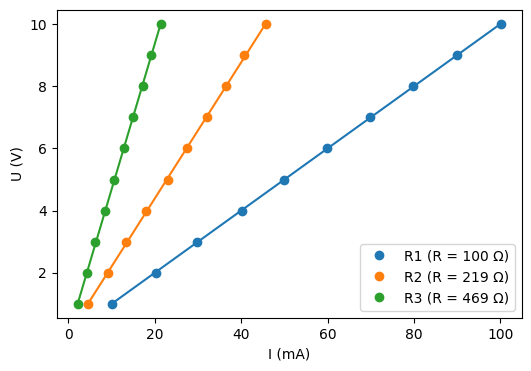

In [48]:
#@title Solution { display-mode: "form" }
print(donnees_ohm.groupby('resistance').size())

donnees_ohm['I_A'] = donnees_ohm['I_mA'] / 1000

plt.figure(figsize=(6, 4))
for nom, groupe in donnees_ohm.groupby('resistance'):
    pente, ordonnee = np.polyfit(groupe['I_A'], groupe['U_V'], 1)
    print(f"{nom} : R = {pente:.1f} Ω")
    plt.plot(groupe['I_A'] * 1000, groupe['U_V'], 'o', label=f"{nom} (R = {pente:.0f} Ω)")
    plt.plot(groupe['I_A'] * 1000, pente * groupe['I_A'] + ordonnee, '-', color=plt.gca().lines[-1].get_color())
plt.xlabel("I (mA)"); plt.ylabel("U (V)"); plt.legend()
plt.show()